# Задание 1. Выявление подозрительных попыток входа в информационную систему
 
**Тема:** анализ событий авторизации сотрудников (UEBA)  
**Цель:** выполнить бизнес- и ML-постановку, выбрать метрики качества, провести EDA.



## 1. Постановка задачи

### Бизнес-постановка

Сотрудники организации входят в информационные системы в разное время, с разных устройств и из разных мест. Среди обычных входов могут встречаться попытки несанкционированного доступа. Нужен простой механизм, который **отмечает подозрительные события** для последующей проверки специалистом по ИБ. Это помогает сократить объём ручного просмотра журналов и быстрее заметить потенциально опасные входы. Автоматически блокировать учётные записи на данном этапе не планируется.

### ML-постановка

**Тип задачи — бинарная классификация с учителем (supervised learning).** По параметрам одного события авторизации требуется предсказать метку `is_suspicious`: `0` — обычное событие, `1` — подозрительное. На текущем этапе модель не обучается: требуется исследовать данные и определить подход к дальнейшей работе.

### Набор данных

Файл `auth_events.csv` содержит **2 400 учебных синтетических событий** с заранее заданной разметкой. Значения получены воспроизводимым генератором (seed=42). Поскольку данные искусственные, выводы из EDA относятся только к этому учебному примеру.

| Поле | Смысл |
|:---|:---|
| `event_id` | идентификатор события|
| `hour` | час входа от 0 до 23 |
| `failed_attempts_24h` | количество неудачных попыток за последние сутки |
| `new_device` | вход с нового устройства (0/1) |
| `unusual_country` | вход из непривычной страны (0/1, возможен пропуск) |
| `vpn_used` | использовался VPN (0/1) |
| `is_suspicious` | целевая метка (0 — обычный вход, 1 — подозрительный) |

## 2. Метрика качества

**Основная метрика — F2-score для класса `1` (подозрительный вход).** Она делает больший акцент на *Recall* (доле найденных подозрительных входов), потому что пропущенная подозрительная авторизация потенциально опаснее дополнительного уведомления специалисту ИБ. При этом F2, в отличие от одного только Recall, учитывает и ложные тревоги.

**Дополнительные метрики — Precision и Recall для класса `1`, а также PR-AUC (площадь под кривой Precision–Recall).** Precision помогает оценить нагрузку на аналитика от ложных тревог, Recall — риск пропуска подозрительных событий, PR-AUC удобна при возможном дисбалансе классов. Accuracy не стоит брать как единственную метрику: большинство событий обычно относится к норме.

Формула: $F_2 = \frac{5 \cdot Precision \cdot Recall}{4 \cdot Precision + Recall}$.

*На этом этапе численные значения метрик не рассчитываются: для этого требуется обучить и проверить модель, что выходит за рамки данного задания.*

## 3. EDA — разведочный анализ данных

EDA проводится с помощью `pandas`, `matplotlib` и `seaborn`. Сначала изучим размер, типы столбцов, пропуски, дубликаты идентификаторов и основные описательные статистики, затем визуализируем распределения и связи с меткой.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'


possible_paths = [Path('auth_events.csv'), Path('ML_Задание_1_Авторизации/auth_events.csv')]
data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Файл auth_events.csv должен лежать рядом с ноутбуком.')

df = pd.read_csv(data_path)
print('Размер набора данных:', df.shape)
display(df.head(7))

Размер набора данных: (2400, 7)


,event_id,hour,failed_attempts_24h,new_device,unusual_country,vpn_used,is_suspicious
0,EVT00001,16,0,0,0.0,0,0
1,EVT00002,11,0,0,0.0,0,0
2,EVT00003,11,0,0,0.0,0,0
3,EVT00004,9,2,1,0.0,0,0
4,EVT00005,20,1,1,0.0,0,0
5,EVT00006,14,0,0,0.0,0,0
6,EVT00007,19,1,0,0.0,0,0


In [2]:
print('Типы данных и количество непустых значений:')
df.info()
print('\nПропуски по столбцам:')
display(df.isna().sum().to_frame('Пропусков'))
print('\nПовторяющиеся ID:', df['event_id'].duplicated().sum())
print('Повторяющиеся наборы признаков не считаем дублями событий:')
print('разные входы могут иметь одинаковые характеристики.')
print('\nОписательная статистика:')
display(df.describe().round(2))

Типы данных и количество непустых значений:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   event_id             2400 non-null   object 
 1   hour                 2400 non-null   int64  
 2   failed_attempts_24h  2400 non-null   int64  
 3   new_device           2400 non-null   int64  
 4   unusual_country      2363 non-null   float64
 5   vpn_used             2400 non-null   int64  
 6   is_suspicious        2400 non-null   int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 131.4+ KB

Пропуски по столбцам:


,Пропусков
event_id,0
hour,0
failed_attempts_24h,0
new_device,0
unusual_country,37
vpn_used,0
is_suspicious,0



Повторяющиеся ID: 0
Повторяющиеся наборы признаков не считаем дублями событий:
разные входы могут иметь одинаковые характеристики.

Описательная статистика:


,hour,failed_attempts_24h,new_device,unusual_country,vpn_used,is_suspicious
count,2400.00,2400.00,2400.00,2363.00,2400.00,2400.00
mean,12.52,0.95,0.15,0.07,0.21,0.08
std,5.55,1.31,0.36,0.26,0.41,0.27
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,9.00,0.00,0.00,0.00,0.00,0.00
50%,13.00,1.00,0.00,0.00,0.00,0.00
75%,17.00,1.00,0.00,0.00,0.00,0.00
max,23.00,13.00,1.00,1.00,1.00,1.00


**Комментарий.** В исходных признаках есть небольшое число пропусков в `unusual_country`. Значит, при последующем обучении нужно будет обработать неизвестное значение, например выделить отдельный индикатор «страна не определена»; заменять пропуск нулём без объяснения нежелательно. Идентификатор события `event_id` не несёт информации о безопасности самого входа и должен быть исключён из входных признаков модели.

Распределение классов:


,Количество,"Доля, %"
is_suspicious,,
Обычные,2204,91.8
Подозрительные,196,8.2


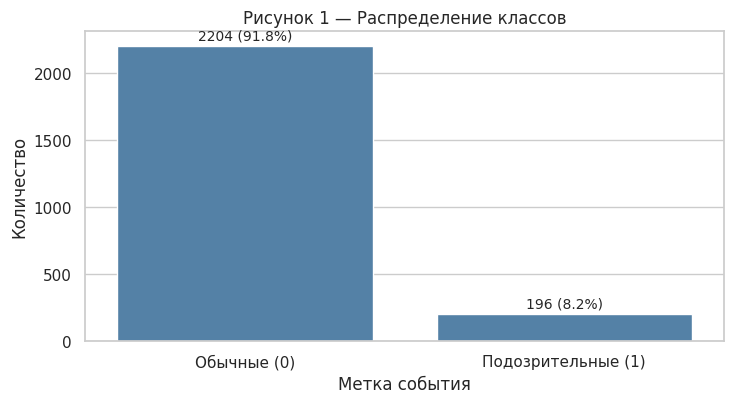

In [3]:
class_counts = df['is_suspicious'].value_counts().sort_index()
class_percent = (100 * class_counts / len(df)).round(1)
print('Распределение классов:')
display(pd.DataFrame({'Количество': class_counts, 'Доля, %': class_percent}).rename(index={0:'Обычные',1:'Подозрительные'}))

plt.figure(figsize=(7.5, 4.2))
ax = sns.countplot(data=df, x='is_suspicious', order=[0, 1], color='steelblue')
ax.set_xticks([0, 1], ['Обычные (0)', 'Подозрительные (1)'])
ax.set(xlabel='Метка события', ylabel='Количество', title='Рисунок 1 — Распределение классов')
for bar in ax.patches:
    value = int(bar.get_height())
    ax.annotate(f'{value} ({value / len(df):.1%})',
                (bar.get_x() + bar.get_width()/2, value),
                xytext=(0, 5), textcoords='offset points', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

**Комментарий.** Если подозрительных входов заметно меньше, чем обычных, образуется дисбаланс классов. В дальнейшем целесообразно применить стратифицированное разделение на обучающую и тестовую выборки, а оценку модели проводить по F2/Recall/Precision и PR-AUC, не ограничиваясь Accuracy.

Неудачные попытки входа:


,count,mean,median,max
is_suspicious,,,,
Обычные,2204,0.83,1.0,13
Подозрительные,196,2.30,2.0,11


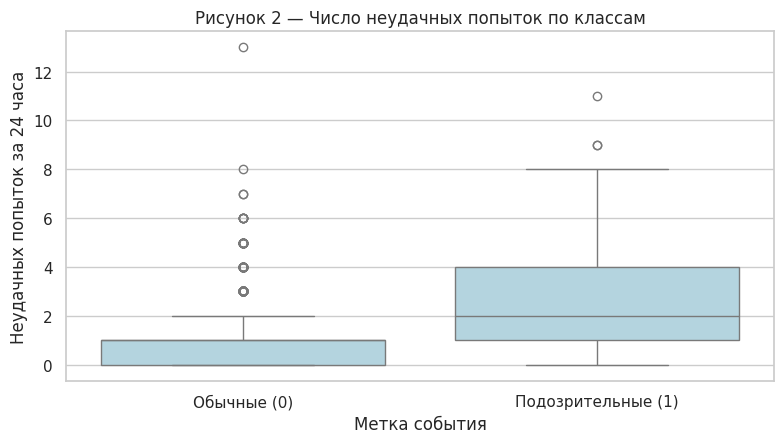

In [4]:
print('Неудачные попытки входа:')
display(df.groupby('is_suspicious')['failed_attempts_24h'].agg(['count', 'mean', 'median', 'max']).round(2).rename(index={0:'Обычные',1:'Подозрительные'}))
plt.figure(figsize=(8, 4.6))
sns.boxplot(data=df, x='is_suspicious', y='failed_attempts_24h', order=[0, 1], showfliers=True, color='lightblue')
plt.xticks([0, 1], ['Обычные (0)', 'Подозрительные (1)'])
plt.xlabel('Метка события')
plt.ylabel('Неудачных попыток за 24 часа')
plt.title('Рисунок 2 — Число неудачных попыток по классам')
plt.tight_layout()
plt.show()

**Комментарий.** Можно проверить, имеют ли подозрительные входы более высокое число неудачных попыток. Значения с большим количеством неудачных попыток не следует удалять автоматически как «ошибочные выбросы»: именно они могут быть важным сигналом подбора пароля. Для моделирования стоит сравнить распределения по классам.

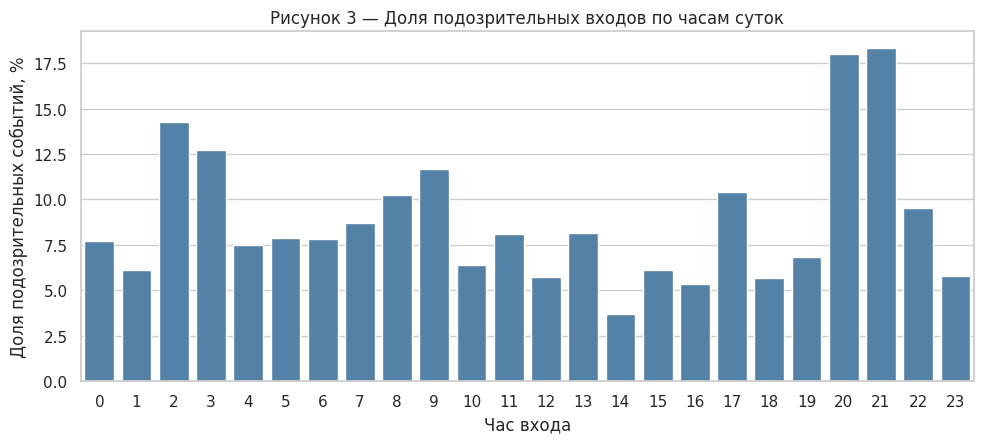

Доля подозрительных событий днём и вне рабочего времени:


,count,mean,"Доля, %"
night_login,,,
08:00–19:59,1809,0.073521,7.4
20:00–07:59,591,0.106599,10.7


In [5]:
# Ночными условно считаем часы 20:00–07:59.
df['night_login'] = (~df['hour'].between(8, 19)).astype(int)
by_hour = df.groupby('hour')['is_suspicious'].agg(['mean', 'count']).reset_index()
by_hour['percent'] = by_hour['mean'] * 100
plt.figure(figsize=(10, 4.6))
sns.barplot(data=by_hour, x='hour', y='percent', color='steelblue')
plt.xlabel('Час входа')
plt.ylabel('Доля подозрительных событий, %')
plt.title('Рисунок 3 — Доля подозрительных входов по часам суток')
plt.tight_layout()
plt.show()

print('Доля подозрительных событий днём и вне рабочего времени:')
display((df.groupby('night_login')['is_suspicious'].agg(['count','mean'])
    .assign(**{'Доля, %':lambda x: (x['mean']*100).round(1)})
    .rename(index={0:'08:00–19:59',1:'20:00–07:59'})))

**Комментарий.** Вход в необычное время может повышать приоритет проверки, но сам по себе не доказывает компрометацию: сотрудники могут работать посменно или удалённо. Поэтому час входа лучше использовать вместе с другими признаками.

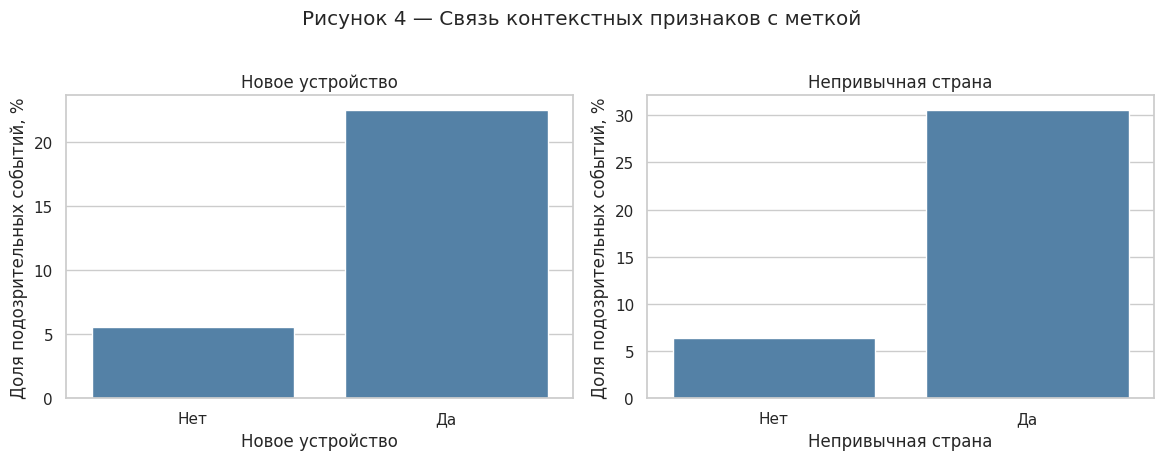

Доли подозрительных событий по двум признакам (пропуски отдельно):

 new_device


is_suspicious,0,1
new_device,,
0,0.944,0.056
1,0.774,0.226



 unusual_country


is_suspicious,0,1
unusual_country,,
-1.0,0.865,0.135
0.0,0.937,0.063
1.0,0.694,0.306


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5))
for ax, feature, title in [
    (axes[0], 'new_device', 'Новое устройство'),
    (axes[1], 'unusual_country', 'Непривычная страна')
]:
    part = df.dropna(subset=[feature]).groupby(feature)['is_suspicious'].mean().reset_index()
    part['Доля, %'] = part['is_suspicious'] * 100
    sns.barplot(data=part, x=feature, y='Доля, %', ax=ax, color='steelblue')
    ax.set_xticks([0, 1], ['Нет', 'Да'])
    ax.set_xlabel(title)
    ax.set_ylabel('Доля подозрительных событий, %')
    ax.set_title(title)
fig.suptitle('Рисунок 4 — Связь контекстных признаков с меткой', y=1.02)
plt.tight_layout()
plt.show()

print('Доли подозрительных событий по двум признакам (пропуски отдельно):')
for col in ['new_device', 'unusual_country']:
    print('\n', col)
    display(pd.crosstab(df[col].fillna(-1), df['is_suspicious'], normalize='index').round(3))

**Комментарий.** Вход с нового устройства или из непривычной страны может быть связан с повышенным риском. Однако здесь речь лишь об ассоциации в искусственно созданном наборе: переносить такие проценты на реальные журналы без проверки нельзя. Пропуски геолокации полезно анализировать как отдельную категорию.

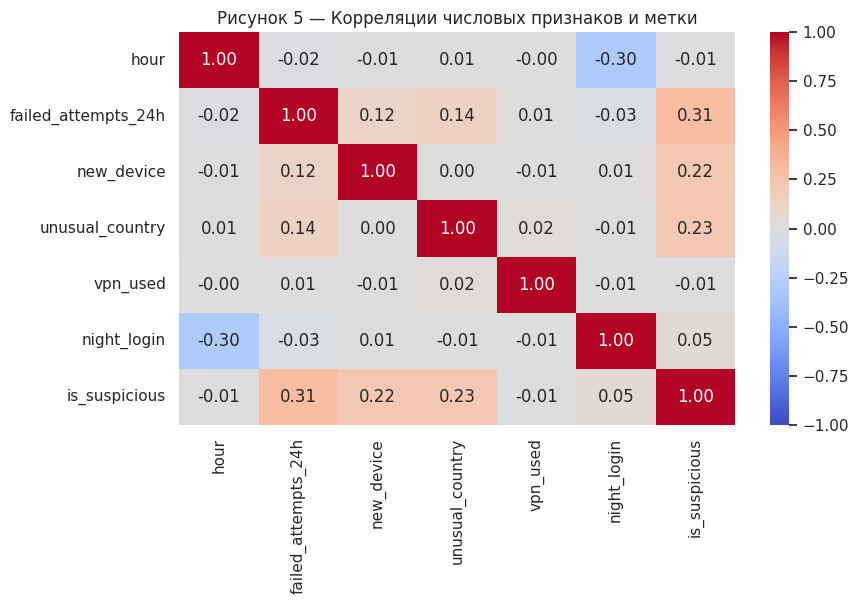

In [7]:
numeric_cols = ['hour','failed_attempts_24h','new_device','unusual_country','vpn_used','night_login','is_suspicious']
correlation = df[numeric_cols].corr()
plt.figure(figsize=(9, 6.2))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Рисунок 5 — Корреляции числовых признаков и метки')
plt.tight_layout()
plt.show()

**Комментарий.** Тепловая карта позволяет увидеть линейные связи между числовыми и бинарными переменными. Корреляция не означает причинность. Признаки `hour` и `night_login` связаны по смыслу, поэтому при дальнейшем построении модели желательно проверить, нужны ли оба; `event_id` не включается в анализ корреляций.